In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
from src.utils import load_data
from src.preprocessing import (
    encode_categorical_variables,
    split_features_target,
)
from src.modelling import (
    split_train_test,
    train_logistic_regression,
    train_random_forest,
    train_xgboost,
    predict_model,
)
from src.config import HEART_DATA_PATH

df = load_data(HEART_DATA_PATH)

encoded_df = encode_categorical_variables(df)

X, y = split_features_target(
    encoded_df,
    "HeartDisease",
)

X_train, X_test, y_train, y_test = split_train_test(
    X,
    y,
)

In [3]:
lr_model = train_logistic_regression(
    X_train,
    y_train,
)

rf_model = train_random_forest(
    X_train,
    y_train,
)

xgb_model = train_xgboost(
    X_train,
    y_train,
)

In [4]:
lr_pred, lr_prob = predict_model(
    lr_model,
    X_test,
)

rf_pred, rf_prob = predict_model(
    rf_model,
    X_test,
)

xgb_pred, xgb_prob = predict_model(
    xgb_model,
    X_test,
)

In [5]:
from src.config import FIGURES_DIR

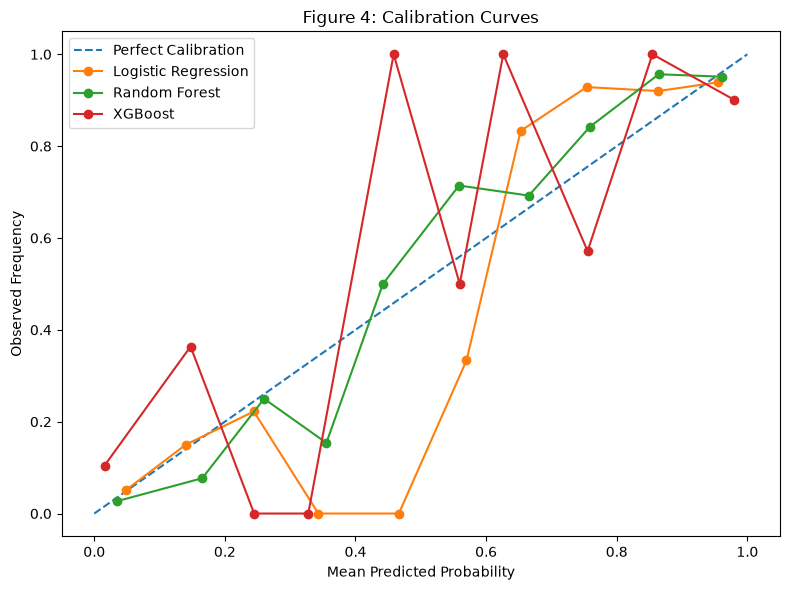

In [6]:
#Temporary test cell
from src.calibration import plot_calibration_curve

plot_calibration_curve(
    models={
        "Logistic Regression": lr_prob,
        "Random Forest": rf_prob,
        "XGBoost": xgb_prob,
    },
    y_true=y_test,
    output_path=FIGURES_DIR / "test_calibration_curve.png",
)

In [7]:
#Temporary test cell
from src.calibration import (
    create_calibration_metrics_table,
    interpret_validation_illusion,
)

calibration_table = create_calibration_metrics_table(
    model_probabilities={
        "Logistic Regression": lr_prob,
        "Random Forest": rf_prob,
        "XGBoost": xgb_prob,
    },
    y_true=y_test,
)

calibration_table

,Model,Brier Score
0,Logistic Regression,0.096
1,Random Forest,0.100
2,XGBoost,0.115


In [8]:
interpretation = interpret_validation_illusion(
    calibration_table
)

print(interpretation)

Logistic Regression achieved the lowest Brier Score (0.096), indicating the most reliable probability estimates among the evaluated models. Differences in calibration performance demonstrate that strong predictive accuracy alone does not guarantee reliable probabilistic predictions, illustrating the concept of Validation Illusion.


# Section 4.3

# Validation Illusion

## Objective

Evaluate whether predictive models that demonstrate strong classification performance also produce reliable probability estimates.

This experiment operationalises the governance mechanism of Validation Illusion by examining model calibration using probabilistic evaluation metrics.

## Research Question

Do conventional validation metrics provide sufficient evidence that a predictive model produces reliable probabilistic estimates suitable for governance decision-making?

## Theory Link

This experiment operationalises Section 4.3 of the paper.

Validation Illusion occurs when high predictive performance creates the impression of trustworthy decision support despite poorly calibrated probability estimates.

Calibration analysis provides an additional governance-oriented evaluation by comparing predicted probabilities with observed outcomes.

## Dataset Description

The experiment uses the Heart Disease Prediction Dataset.

Target Variable

- HeartDisease

Predictor variables include demographic, clinical, and diagnostic attributes previously prepared during preprocessing.

In [9]:
#Imports
from src.utils import load_data

from src.preprocessing import (
    encode_categorical_variables,
    split_features_target,
)

from src.modelling import (
    split_train_test,
    train_logistic_regression,
    train_random_forest,
    train_xgboost,
    predict_model,
)

from src.calibration import (
    create_calibration_metrics_table,
    plot_calibration_curve,
    interpret_validation_illusion,
)

from src.config import (
    HEART_DATA_PATH,
    FIGURES_DIR,
)
from src.config import TABLES_DIR

In [10]:
#Configuration
RANDOM_STATE = 42

In [11]:
#Data Loading
df = load_data(
    HEART_DATA_PATH
)

In [12]:
#Data Audit
print(df.shape)

df.head()

(918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


## Preprocessing

The dataset is encoded into a machine-learning compatible format before splitting into predictor variables and the target variable.

In [13]:
encoded_df = encode_categorical_variables(
    df
)

X, y = split_features_target(
    encoded_df,
    "HeartDisease",
)

X_train, X_test, y_train, y_test = split_train_test(
    X,
    y,
)

## Experiment

Three predictive models are trained using identical training data.

The predicted probabilities generated by each model are used to evaluate calibration performance.

In [14]:
lr_model = train_logistic_regression(
    X_train,
    y_train,
)

rf_model = train_random_forest(
    X_train,
    y_train,
)

xgb_model = train_xgboost(
    X_train,
    y_train,
)

In [15]:
lr_pred, lr_prob = predict_model(
    lr_model,
    X_test,
)

rf_pred, rf_prob = predict_model(
    rf_model,
    X_test,
)

xgb_pred, xgb_prob = predict_model(
    xgb_model,
    X_test,
)

## Robustness Analysis

Calibration analysis evaluates the agreement between predicted probabilities and observed outcomes.

Unlike conventional classification metrics, calibration assesses the reliability of probability estimates for governance-oriented decision-making.

In [16]:
calibration_table = create_calibration_metrics_table(
    model_probabilities={
        "Logistic Regression": lr_prob,
        "Random Forest": rf_prob,
        "XGBoost": xgb_prob,
    },
    y_true=y_test,
)

calibration_table

,Model,Brier Score
0,Logistic Regression,0.096
1,Random Forest,0.100
2,XGBoost,0.115


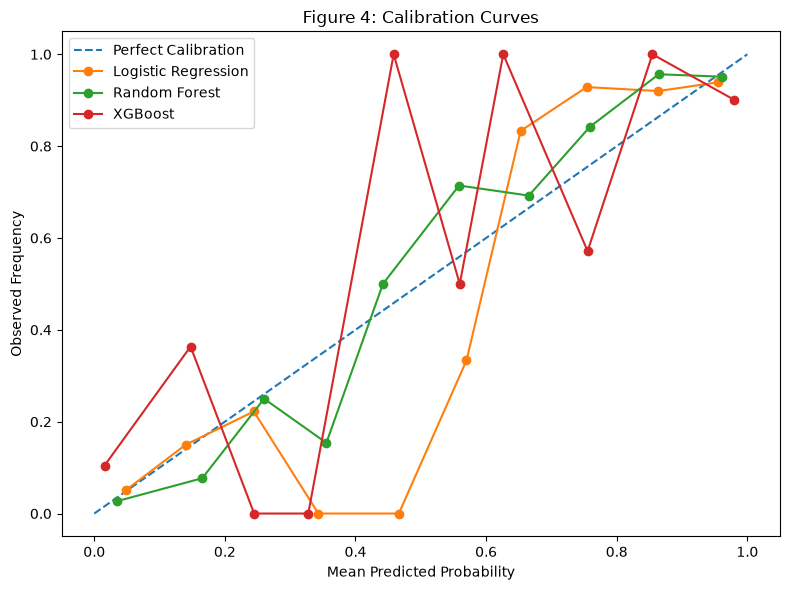

In [17]:
plot_calibration_curve(
    models={
        "Logistic Regression": lr_prob,
        "Random Forest": rf_prob,
        "XGBoost": xgb_prob,
    },
    y_true=y_test,
    output_path=FIGURES_DIR / "figure_4_calibration_curves.png",
)

## Results

The calibration metrics and calibration curves summarise the probabilistic reliability of each predictive model.

Lower Brier Scores indicate better calibration and more reliable probability estimates.

In [18]:
print(calibration_table)

                 Model  Brier Score
0  Logistic Regression        0.096
1        Random Forest        0.100
2              XGBoost        0.115


## Interpretation

The calibration analysis demonstrates that predictive accuracy alone is insufficient for evaluating models used in governance contexts.

Models producing similar classification performance may generate probability estimates with substantially different levels of reliability.

This illustrates the concept of Validation Illusion, whereby conventional validation metrics can create unwarranted confidence in automated decision support.

In [19]:
interpretation = interpret_validation_illusion(
    calibration_table
)

print(interpretation)

Logistic Regression achieved the lowest Brier Score (0.096), indicating the most reliable probability estimates among the evaluated models. Differences in calibration performance demonstrate that strong predictive accuracy alone does not guarantee reliable probabilistic predictions, illustrating the concept of Validation Illusion.


## Save Outputs

Publication-ready outputs are automatically saved for later inclusion within the manuscript and Streamlit dashboard.

In [20]:
calibration_table.to_csv(
    TABLES_DIR / "table_5_calibration_metrics.csv",
    index=False,
)

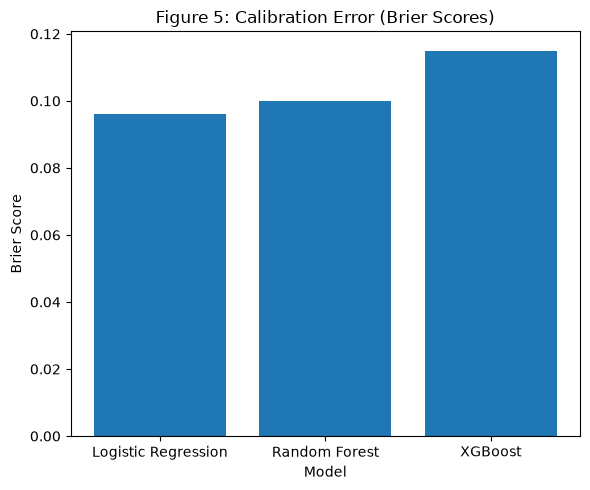

: 

In [ ]:
from src.calibration import plot_brier_scores
from src.config import FIGURES_DIR

plot_brier_scores(
    calibration_table,
    FIGURES_DIR / "figure_5_brier_scores.png",
)

## Conclusion

This experiment evaluated the calibration performance of Logistic Regression, Random Forest, and XGBoost using Brier Scores and calibration curves.

The results demonstrate that strong predictive performance does not necessarily imply reliable probabilistic estimates. Calibration analysis therefore provides an essential governance-oriented perspective that complements conventional validation metrics.

The generated calibration metrics and visualisations establish the empirical basis for evaluating Validation Illusion within simulated subjecthood.